# Red Neuronal Multicapa para Predicción de Consumo Energético
### Implementación desde cero con NumPy

**Proyecto Final — Seminario de Sistemas II**
Raúl Hernández Nuñez · 2173770 · IAS · Grupo 002

---

**Objetivo:** predecir el consumo eléctrico de los electrodomésticos de un edificio (`Appliances`, en Wh) a partir de variables de tiempo y clima, usando una red neuronal multicapa programada **sin frameworks de deep learning** (sin TensorFlow, Keras ni PyTorch). Toda la matemática — forward, loss, backpropagation y gradient descent — está escrita con NumPy.

**Arquitectura:** `6 → 16 (ReLU) → 8 (ReLU) → 1 (lineal)`

**Datos:** [UCI Appliances Energy Prediction](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction) — 19,735 mediciones cada 10 minutos de una casa en Bélgica (enero–mayo 2016).

**Estructura del notebook**
1. Cargar datos
2. Preparar datos
3. Clase `NeuralNetwork`
4. Instanciar y entrenar
5. Hacer predicciones
6. Calcular métricas
7. Graficar y comparar contra regresión lineal

## SECCIÓN 1 · Cargar datos

In [1]:
# Paquete oficial de UCI para descargar datasets
!pip install -q ucimlrepo


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
# Librerías
import io
import json
import os
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn SOLO se usa para el modelo de comparación (regresión lineal)
# y para verificar que nuestras métricas hechas a mano son correctas.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

plt.rcParams["figure.dpi"] = 110

In [3]:
def cargar_dataset():
    '''Obtiene el dataset de UCI (id 374). Orden de intentos:
    archivo local -> paquete ucimlrepo -> CSV directo -> ZIP -> subir a mano.'''
    url_csv = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
               "00374/energydata_complete.csv")
    url_zip = ("https://archive.ics.uci.edu/static/public/374/"
               "appliances+energy+prediction.zip")

    # 0) Si ya existe una copia local, se usa esa
    for ruta in ["energydata_complete.csv", "datos/energydata_complete.csv"]:
        if os.path.exists(ruta):
            print(f"Usando archivo local: {ruta}")
            return pd.read_csv(ruta)

    # 1) Paquete oficial ucimlrepo (método recomendado por UCI).
    #    Se usa .data.original porque trae TODAS las columnas juntas, incluida
    #    `date`, que necesitamos para crear hour, dayofweek, is_weekend y month.
    try:
        from ucimlrepo import fetch_ucirepo
        print("Descargando con ucimlrepo (id=374)...")
        appliances_energy_prediction = fetch_ucirepo(id=374)
        return appliances_energy_prediction.data.original.copy()
    except Exception as e:
        print(f"  No se pudo con ucimlrepo ({e}). Probando el CSV directo...")

    # 2) CSV directo
    try:
        print("Descargando CSV desde UCI...")
        return pd.read_csv(url_csv)
    except Exception as e:
        print(f"  No se pudo con la URL directa ({e}). Probando el ZIP...")

    # 3) ZIP oficial
    try:
        with urllib.request.urlopen(url_zip) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        nombre = [n for n in z.namelist() if n.endswith(".csv")][0]
        return pd.read_csv(z.open(nombre))
    except Exception as e:
        print(f"  Tampoco se pudo con el ZIP ({e}).")

    # 4) Subir manualmente (solo funciona en Google Colab)
    from google.colab import files
    print("Sube el archivo energydata_complete.csv:")
    subido = files.upload()
    return pd.read_csv(io.BytesIO(next(iter(subido.values()))))


df = cargar_dataset()
# Por si la fecha viene como índice en lugar de columna
if "date" not in df.columns and df.index.name == "date":
    df = df.reset_index()
print("\nForma del dataset:", df.shape)
df.head()

Descargando con ucimlrepo (id=374)...



Forma del dataset: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-1117:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-1117:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-1117:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-1117:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390
4,2016-01-1117:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [4]:
# Tipos de dato y estadísticas de las columnas que vamos a usar
print(df.dtypes.value_counts(), "\n")
df[["date", "Appliances", "T_out", "RH_out"]].describe()

float64    26
int64       2
str         1
Name: count, dtype: int64 



,Appliances,T_out,RH_out
count,19735.000000,19735.000000,19735.000000
mean,97.694958,7.412580,79.750418
std,102.524891,5.318464,14.901088
min,10.000000,-5.000000,24.000000
25%,50.000000,3.670000,70.333333
50%,60.000000,6.920000,83.666667
75%,100.000000,10.400000,91.666667
max,1080.000000,26.100000,100.000000


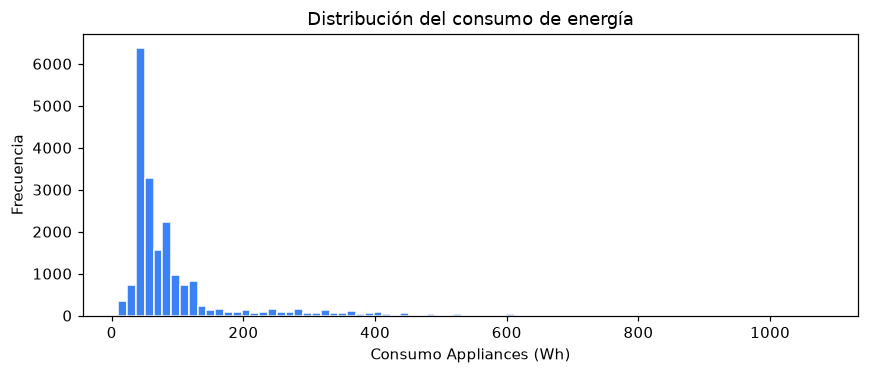

In [5]:
# Distribución del consumo: está muy sesgada (muchos valores bajos y picos
# ocasionales muy altos). Esto hace que el problema sea difícil de predecir.
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["Appliances"], bins=80, color="#3b82f6", edgecolor="white")
ax.set_xlabel("Consumo Appliances (Wh)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución del consumo de energía")
plt.tight_layout()
plt.show()

## SECCIÓN 2 · Preparar datos

El CSV trae una columna `date` (fecha y hora). De ahí **derivamos** cuatro de las seis variables de entrada; las otras dos (`T_out`, `RH_out`) vienen directo del archivo.

| # | Variable | Descripción |
|---|----------|-------------|
| 1 | `hour` | Hora del día (0–23) |
| 2 | `dayofweek` | Día de la semana (0 = lunes, 6 = domingo) |
| 3 | `is_weekend` | 1 si es sábado o domingo |
| 4 | `month` | Mes del año |
| 5 | `T_out` | Temperatura exterior (°C) |
| 6 | `RH_out` | Humedad exterior (%) |

**Target:** `Appliances` — consumo en Wh.

In [6]:
# Crear las variables de tiempo a partir de la fecha
# ucimlrepo a veces trae la fecha pegada a la hora ("2016-01-1117:00:00");
# se agrega el espacio que falta antes de convertirla a fecha
df["date"] = df["date"].astype(str).str.replace(
    r"^(\d{4}-\d{2}-\d{2})(\d)", r"\1 \2", regex=True)
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["dayofweek"] = df["date"].dt.dayofweek
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
df["month"] = df["date"].dt.month

FEATURES = ["hour", "dayofweek", "is_weekend", "month", "T_out", "RH_out"]
TARGET = "Appliances"

X = df[FEATURES].to_numpy(dtype=float)              # (n, 6)
y = df[TARGET].to_numpy(dtype=float).reshape(-1, 1)  # (n, 1)

print("X:", X.shape, " y:", y.shape)
df[FEATURES + [TARGET]].head()

X: (19735, 6)  y: (19735, 1)


,hour,dayofweek,is_weekend,month,T_out,RH_out,Appliances
0,17,0,0,1,6.60,92.0,60
1,17,0,0,1,6.48,92.0,60
2,17,0,0,1,6.37,92.0,50
3,17,0,0,1,6.25,92.0,50
4,17,0,0,1,6.13,92.0,60


### División 70 / 15 / 15 y normalización

- Los datos se **mezclan aleatoriamente** (con semilla fija) y se dividen en entrenamiento (70 %), validación (15 %) y prueba (15 %).
- Se normaliza con *z-score*: `(x − media) / desviación estándar`. La media y la desviación se calculan **solo con el conjunto de entrenamiento** y se aplican igual a validación y prueba; así la red no "ve" información del test por adelantado (*data leakage*).
- El target `y` también se normaliza para entrenar; al final las predicciones se **desnormalizan** para reportar el error en Wh.

In [7]:
def dividir_datos(X, y, train=0.70, val=0.15, seed=SEED):
    '''Mezcla los índices y divide en train / validation / test.'''
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    n_train = int(train * len(X))
    n_val = int(val * len(X))
    i_tr, i_va, i_te = np.split(idx, [n_train, n_train + n_val])
    return X[i_tr], X[i_va], X[i_te], y[i_tr], y[i_va], y[i_te]


def normalizar(X, media=None, desv=None):
    '''Normalización z-score. Si no se dan media/desv, se calculan de X.'''
    if media is None:
        media = X.mean(axis=0)
        desv = X.std(axis=0)
        desv[desv == 0] = 1.0  # evita dividir entre cero
    return (X - media) / desv, media, desv


X_train_raw, X_val_raw, X_test_raw, y_train_raw, y_val_raw, y_test_raw = dividir_datos(X, y)

# Estadísticas SOLO del set de entrenamiento
X_train, X_mean, X_std = normalizar(X_train_raw)
X_val, _, _ = normalizar(X_val_raw, X_mean, X_std)
X_test, _, _ = normalizar(X_test_raw, X_mean, X_std)

y_train, y_mean, y_std = normalizar(y_train_raw)
y_val, _, _ = normalizar(y_val_raw, y_mean, y_std)
y_test, _, _ = normalizar(y_test_raw, y_mean, y_std)


def desnormalizar_y(y_norm):
    '''Regresa las predicciones a la escala original (Wh).'''
    return y_norm * y_std + y_mean


print(f"Entrenamiento: {len(X_train):>6} registros")
print(f"Validación:    {len(X_val):>6} registros")
print(f"Prueba:        {len(X_test):>6} registros")

Entrenamiento:  13814 registros
Validación:      2960 registros
Prueba:          2961 registros


## SECCIÓN 3 · Clase `NeuralNetwork` (desde cero)

### Forward propagation
$$
\begin{aligned}
z_1 &= X W_1 + b_1, & a_1 &= \text{ReLU}(z_1) \\
z_2 &= a_1 W_2 + b_2, & a_2 &= \text{ReLU}(z_2) \\
z_3 &= a_2 W_3 + b_3, & \hat{y} = a_3 &= z_3 \quad \text{(salida lineal)}
\end{aligned}
$$

### Loss
$$\text{MSE} = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i - y_i)^2$$

### Backpropagation (regla de la cadena)
$$
\begin{aligned}
dz_3 &= \tfrac{2}{m}(a_3 - y) & dW_3 &= a_2^\top dz_3 & db_3 &= \textstyle\sum dz_3 \\
dz_2 &= (dz_3 W_3^\top) \odot \text{ReLU}'(z_2) & dW_2 &= a_1^\top dz_2 & db_2 &= \textstyle\sum dz_2 \\
dz_1 &= (dz_2 W_2^\top) \odot \text{ReLU}'(z_1) & dW_1 &= X^\top dz_1 & db_1 &= \textstyle\sum dz_1
\end{aligned}
$$

### Gradient descent
$$W \leftarrow W - \eta \, \frac{\partial L}{\partial W}, \qquad b \leftarrow b - \eta \, \frac{\partial L}{\partial b}$$

**Nota sobre la inicialización de pesos.** El plan original proponía pesos `Normal(0, 0.01)`. Con pesos tan pequeños la señal casi desaparece al cruzar dos capas ReLU y, con *learning rate* 0.01, la red apenas aprende en 5000 épocas. Por eso la clase permite dos modos:
- `init="he"` (**usado por defecto**): `Normal(0, √(2 / n_entradas))`, la inicialización estándar para ReLU (He et al., 2015).
- `init="small"`: `Normal(0, 0.01)`, la del plan original, para poder comparar.

In [8]:
class NeuralNetwork:
    '''Red neuronal multicapa (MLP) para regresión, implementada solo con NumPy.

    Arquitectura usada en el proyecto: [6, 16, 8, 1]
      - Capas ocultas con activación ReLU
      - Capa de salida lineal (regresión de un valor continuo)
    Entrenamiento: MSE + backpropagation + gradient descent (batch completo).
    '''

    def __init__(self, layer_dims, learning_rate=0.01, init="he", seed=SEED):
        '''layer_dims: lista con el número de neuronas por capa, p. ej. [6, 16, 8, 1].
        learning_rate: tamaño del paso de gradient descent.
        init: "he" (recomendado para ReLU) o "small" (Normal(0, 0.01)).'''
        self.layer_dims = layer_dims
        self.learning_rate = learning_rate
        self.init = init
        self.rng = np.random.default_rng(seed)
        self.params = {}      # W1, b1, W2, b2, W3, b3
        self.cache = {}       # valores intermedios del forward (para backprop)
        self.gradients = {}   # dW1, db1, ... calculados en backward
        self.loss_history = []
        self.val_loss_history = []
        self.initialize_weights()

    def initialize_weights(self):
        '''Crea W (aleatorios pequeños) y b (ceros) para cada capa.
        W_l tiene forma (neuronas capa anterior, neuronas capa l).'''
        for l in range(1, len(self.layer_dims)):
            n_in, n_out = self.layer_dims[l - 1], self.layer_dims[l]
            std = np.sqrt(2.0 / n_in) if self.init == "he" else 0.01
            self.params[f"W{l}"] = self.rng.normal(0.0, std, size=(n_in, n_out))
            self.params[f"b{l}"] = np.zeros((1, n_out))

    @staticmethod
    def relu(z):
        '''ReLU: max(0, z) elemento a elemento.'''
        return np.maximum(0, z)

    @staticmethod
    def relu_derivative(z):
        '''Derivada de ReLU: 1 donde z > 0, 0 en otro caso.'''
        return (z > 0).astype(float)

    def forward(self, X):
        '''Propagación hacia adelante. Guarda z y a de cada capa en self.cache
        y regresa la predicción a3 con forma (m, 1).'''
        p = self.params
        z1 = X @ p["W1"] + p["b1"]
        a1 = self.relu(z1)
        z2 = a1 @ p["W2"] + p["b2"]
        a2 = self.relu(z2)
        z3 = a2 @ p["W3"] + p["b3"]
        a3 = z3  # salida lineal: sin activación
        self.cache = {"X": X, "z1": z1, "a1": a1, "z2": z2, "a2": a2, "z3": z3}
        return a3

    @staticmethod
    def mse(predictions, y):
        '''Error cuadrático medio.'''
        return float(np.mean((predictions - y) ** 2))

    def backward(self, X, y, predictions):
        '''Retropropagación: calcula dL/dW y dL/db de las tres capas
        aplicando la regla de la cadena desde la salida hacia la entrada.'''
        m = X.shape[0]
        p, c = self.params, self.cache

        # Capa de salida (lineal). Derivada de MSE respecto a la predicción.
        dz3 = (2.0 / m) * (predictions - y)                 # (m, 1)
        dW3 = c["a2"].T @ dz3                               # (8, 1)
        db3 = dz3.sum(axis=0, keepdims=True)                # (1, 1)

        # Capa oculta 2 (ReLU)
        dz2 = (dz3 @ p["W3"].T) * self.relu_derivative(c["z2"])  # (m, 8)
        dW2 = c["a1"].T @ dz2                                     # (16, 8)
        db2 = dz2.sum(axis=0, keepdims=True)                      # (1, 8)

        # Capa oculta 1 (ReLU)
        dz1 = (dz2 @ p["W2"].T) * self.relu_derivative(c["z1"])  # (m, 16)
        dW1 = X.T @ dz1                                           # (6, 16)
        db1 = dz1.sum(axis=0, keepdims=True)                      # (1, 16)

        self.gradients = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2,
                          "W3": dW3, "b3": db3}

    def update_weights(self):
        '''Gradient descent: parámetro = parámetro - learning_rate * gradiente.'''
        for nombre, grad in self.gradients.items():
            self.params[nombre] -= self.learning_rate * grad

    def train(self, X_train, y_train, epochs, X_val=None, y_val=None, print_every=500):
        '''Loop de entrenamiento con batch completo.
        En cada época: forward -> loss -> backward -> actualizar pesos.'''
        for epoch in range(1, epochs + 1):
            pred = self.forward(X_train)
            loss = self.mse(pred, y_train)
            self.backward(X_train, y_train, pred)
            self.update_weights()
            self.loss_history.append(loss)

            # Loss de validación (solo se mide, no se usa para entrenar)
            if X_val is not None:
                self.val_loss_history.append(self.mse(self.predict(X_val), y_val))

            if print_every and (epoch == 1 or epoch % print_every == 0):
                msg = f"Época {epoch:>5}/{epochs} | loss train: {loss:.4f}"
                if X_val is not None:
                    msg += f" | loss val: {self.val_loss_history[-1]:.4f}"
                print(msg)
        return self.loss_history

    def predict(self, X):
        '''Predicción para nuevos datos (forward sin modificar la caché de entrenamiento).'''
        cache_entrenamiento = self.cache
        pred = self.forward(X)
        self.cache = cache_entrenamiento
        return pred

### Verificación del backpropagation (gradient check)

Para demostrar que las derivadas escritas a mano son correctas, se comparan contra una aproximación numérica:
$$\frac{\partial L}{\partial w} \approx \frac{L(w+\varepsilon) - L(w-\varepsilon)}{2\varepsilon}$$
Si la diferencia relativa es muy pequeña (< 1e-6), el backpropagation está bien implementado.

**Cuidado con ReLU:** en $z = 0$ la función tiene una "esquina" y no es derivable. Si al mover un peso $\pm\varepsilon$ alguna neurona cruza de apagada a encendida, la aproximación numérica da un valor falso aunque el backpropagation esté bien. Por eso esos pesos se omiten de la comparación y se informa cuántos fueron. Con los datos reales en GitHub Actions, la versión sin esta protección marcó 4.9e-05, y la misma prueba en otra computadora dio 1.1e-11: la diferencia venía solo de esas esquinas.

In [9]:
def gradient_check(red, X, y, eps=1e-5):
    '''Compara los gradientes analíticos (backward) con los numéricos.
    ReLU no es derivable en z = 0. Si al mover un peso ±eps alguna neurona pasa
    de apagada a encendida (o al revés), la aproximación numérica no sirve para
    ese peso, así que se omite de la comparación y se cuenta.'''
    pred = red.forward(X)
    red.backward(X, y, pred)
    activas = [red.cache["z1"] > 0, red.cache["z2"] > 0]

    def evaluar():
        loss = red.mse(red.forward(X), y)
        cruzo = any(not np.array_equal(red.cache[z] > 0, a)
                    for z, a in zip(["z1", "z2"], activas))
        return loss, cruzo

    analiticos, numericos, omitidos = [], [], 0
    for nombre, param in red.params.items():
        for i in np.ndindex(param.shape):
            original = param[i]
            param[i] = original + eps
            loss_mas, cruzo_mas = evaluar()
            param[i] = original - eps
            loss_menos, cruzo_menos = evaluar()
            param[i] = original
            if cruzo_mas or cruzo_menos:
                omitidos += 1
                continue
            numericos.append((loss_mas - loss_menos) / (2 * eps))
            analiticos.append(red.gradients[nombre][i])
    a, n = np.array(analiticos), np.array(numericos)
    return np.linalg.norm(a - n) / (np.linalg.norm(a) + np.linalg.norm(n)), omitidos


red_prueba = NeuralNetwork([6, 16, 8, 1], init="he")
dif, omitidos = gradient_check(red_prueba, X_train[:50], y_train[:50])
total = sum(p.size for p in red_prueba.params.values())
print(f"Parámetros comparados: {total - omitidos} de {total} "
      f"({omitidos} omitidos por la esquina de ReLU en z = 0)")
print(f"Diferencia relativa: {dif:.2e} ->", "✅ backprop correcto" if dif < 1e-6 else "❌ revisar")

Parámetros comparados: 255 de 257 (2 omitidos por la esquina de ReLU en z = 0)
Diferencia relativa: 1.04e-11 -> ✅ backprop correcto


## SECCIÓN 4 · Instanciar y entrenar

Hiperparámetros del proyecto:

| Parámetro | Valor |
|-----------|-------|
| Arquitectura | `[6, 16, 8, 1]` |
| Learning rate | 0.01 |
| Épocas | 5000 |
| Batch | todo el set de entrenamiento |
| Activación oculta / salida | ReLU / lineal |
| Inicialización | He (ver nota de la Sección 3) |

In [10]:
LEARNING_RATE = 0.01
EPOCHS = 5000

red = NeuralNetwork([6, 16, 8, 1], learning_rate=LEARNING_RATE, init="he")
loss_history = red.train(X_train, y_train, EPOCHS, X_val=X_val, y_val=y_val)

Época     1/5000 | loss train: 2.5425 | loss val: 1.7915


Época   500/5000 | loss train: 0.9263 | loss val: 0.8255


Época  1000/5000 | loss train: 0.8972 | loss val: 0.8020


Época  1500/5000 | loss train: 0.8799 | loss val: 0.7880


Época  2000/5000 | loss train: 0.8703 | loss val: 0.7781


...

Época  3000/5000 | loss train: 0.8604 | loss val: 0.7688


Época  3500/5000 | loss train: 0.8570 | loss val: 0.7659


Época  4000/5000 | loss train: 0.8538 | loss val: 0.7634


Época  4500/5000 | loss train: 0.8509 | loss val: 0.7615


Época  5000/5000 | loss train: 0.8481 | loss val: 0.7599


**Comparación de inicializaciones.** Se entrena una segunda red, igual pero con la inicialización original `Normal(0, 0.01)`, para justificar el cambio a He.

In [11]:
red_small = NeuralNetwork([6, 16, 8, 1], learning_rate=LEARNING_RATE, init="small")
red_small.train(X_train, y_train, EPOCHS, X_val=X_val, y_val=y_val, print_every=0)

print(f"Loss final (train, normalizado) con init He:          {red.loss_history[-1]:.4f}")
print(f"Loss final (train, normalizado) con init Normal(0,.01): {red_small.loss_history[-1]:.4f}")

Loss final (train, normalizado) con init He:          0.8481
Loss final (train, normalizado) con init Normal(0,.01): 1.0000


## SECCIÓN 5 · Hacer predicciones

Se predice sobre los tres conjuntos y se regresa todo a Wh.

In [12]:
pred_train = desnormalizar_y(red.predict(X_train))
pred_val = desnormalizar_y(red.predict(X_val))
pred_test = desnormalizar_y(red.predict(X_test))

# Valores reales en Wh (los originales, sin normalizar)
real_train, real_val, real_test = y_train_raw, y_val_raw, y_test_raw

pd.DataFrame({
    "Real (Wh)": real_test[:10].ravel(),
    "Predicción (Wh)": pred_test[:10].ravel().round(1),
})

,Real (Wh),Predicción (Wh)
0,80.0,86.9
1,20.0,49.3
2,50.0,42.1
3,90.0,78.2
4,130.0,148.1
5,50.0,137.4
6,60.0,87.1
7,70.0,114.4
8,140.0,114.4
9,360.0,75.8


## SECCIÓN 6 · Calcular métricas

Implementadas a mano con NumPy:
- **MAE** = mean(|y_real − y_pred|) — error promedio en Wh.
- **RMSE** = √mean((y_real − y_pred)²) — castiga más los errores grandes.
- **R²** = 1 − SS_res / SS_tot — proporción de la variación del consumo que explica el modelo (1 = perfecto, 0 = igual que predecir siempre el promedio).

In [13]:
def mae(y_real, y_pred):
    return float(np.mean(np.abs(y_real - y_pred)))


def rmse(y_real, y_pred):
    return float(np.sqrt(np.mean((y_real - y_pred) ** 2)))


def r2(y_real, y_pred):
    ss_res = np.sum((y_real - y_pred) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return float(1 - ss_res / ss_tot)


def metricas(y_real, y_pred):
    return {"MAE (Wh)": mae(y_real, y_pred),
            "RMSE (Wh)": rmse(y_real, y_pred),
            "R²": r2(y_real, y_pred)}


tabla_red = pd.DataFrame({
    "Entrenamiento": metricas(real_train, pred_train),
    "Validación": metricas(real_val, pred_val),
    "Prueba": metricas(real_test, pred_test),
}).T
print("Métricas de la red neuronal")
tabla_red.round(3)

Métricas de la red neuronal


,MAE (Wh),RMSE (Wh),R²
Entrenamiento,54.008,95.815,0.152
Validación,52.425,90.696,0.130
Prueba,52.949,92.131,0.159


In [14]:
# Verificación: nuestras métricas coinciden con las de scikit-learn
assert np.isclose(mae(real_test, pred_test), mean_absolute_error(real_test, pred_test))
assert np.isclose(rmse(real_test, pred_test), np.sqrt(mean_squared_error(real_test, pred_test)))
assert np.isclose(r2(real_test, pred_test), r2_score(real_test, pred_test))
print("✅ Las métricas hechas a mano coinciden con scikit-learn")

m = metricas(real_test, pred_test)
print(f"\nRESULTADOS EN TEST (datos que la red nunca vio)")
print(f"  MAE : {m['MAE (Wh)']:.2f} Wh")
print(f"  RMSE: {m['RMSE (Wh)']:.2f} Wh")
print(f"  R²  : {m['R²']:.4f}")

✅ Las métricas hechas a mano coinciden con scikit-learn

RESULTADOS EN TEST (datos que la red nunca vio)
  MAE : 52.95 Wh
  RMSE: 92.13 Wh
  R²  : 0.1594


## SECCIÓN 7 · Graficar y comparar

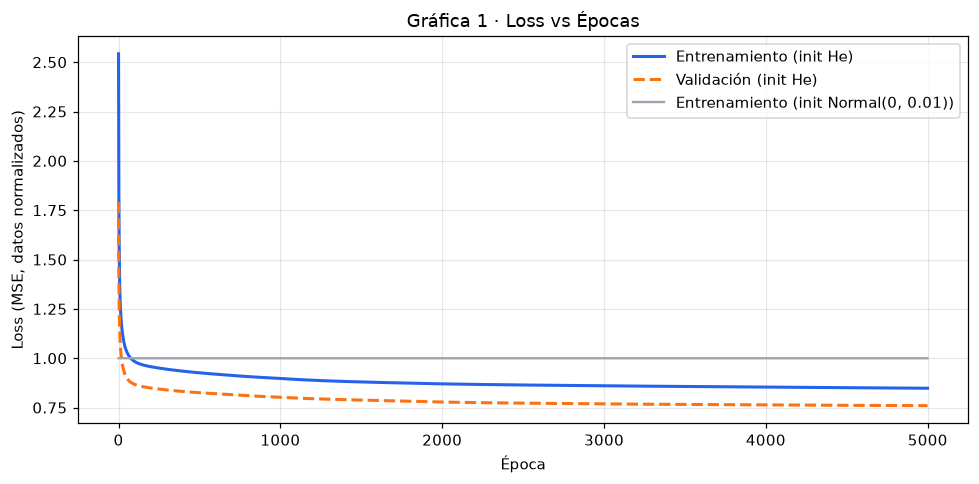

In [15]:
os.makedirs("resultados", exist_ok=True)

# Gráfica 1: Loss vs épocas
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(red.loss_history, label="Entrenamiento (init He)", color="#2563eb", lw=2)
ax.plot(red.val_loss_history, label="Validación (init He)", color="#f97316", lw=2, ls="--")
ax.plot(red_small.loss_history, label="Entrenamiento (init Normal(0, 0.01))",
        color="#9ca3af", lw=1.5)
ax.set_xlabel("Época")
ax.set_ylabel("Loss (MSE, datos normalizados)")
ax.set_title("Gráfica 1 · Loss vs Épocas")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("resultados/grafica_loss.png", dpi=150)
plt.show()

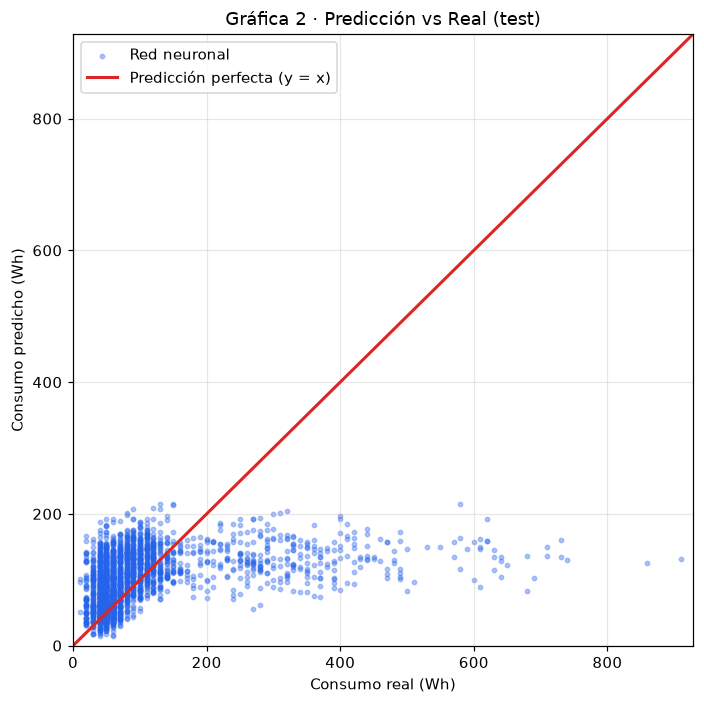

In [16]:
# Gráfica 2: Predicción vs Real (test)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(real_test, pred_test, s=8, alpha=0.35, color="#2563eb", label="Red neuronal")
lim = [0, max(real_test.max(), pred_test.max()) * 1.02]
ax.plot(lim, lim, color="#dc2626", lw=2, label="Predicción perfecta (y = x)")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Consumo real (Wh)")
ax.set_ylabel("Consumo predicho (Wh)")
ax.set_title("Gráfica 2 · Predicción vs Real (test)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("resultados/grafica_prediccion.png", dpi=150)
plt.show()

### Comparación contra regresión lineal

Se entrena una regresión lineal de scikit-learn con **exactamente los mismos datos** (mismas variables, misma división y misma normalización) para medir cuánto mejora la red neuronal.

In [17]:
lin = LinearRegression()
lin.fit(X_train, y_train)
pred_lin_test = desnormalizar_y(lin.predict(X_test))

m_red = metricas(real_test, pred_test)
m_lin = metricas(real_test, pred_lin_test)

comparacion = pd.DataFrame({"Red neuronal": m_red, "Regresión lineal": m_lin}).T
comparacion.loc["Mejora de la red"] = [
    f"{(1 - m_red['MAE (Wh)'] / m_lin['MAE (Wh)']) * 100:.1f} % menos error",
    f"{(1 - m_red['RMSE (Wh)'] / m_lin['RMSE (Wh)']) * 100:.1f} % menos error",
    f"+{m_red['R²'] - m_lin['R²']:.3f}",
]
print("Comparación en el set de prueba")
comparacion

Comparación en el set de prueba


,MAE (Wh),RMSE (Wh),R²
Red neuronal,52.948669,92.130729,0.159435
Regresión lineal,55.640796,97.401526,0.060507
Mejora de la red,4.8 % menos error,5.4 % menos error,+0.099


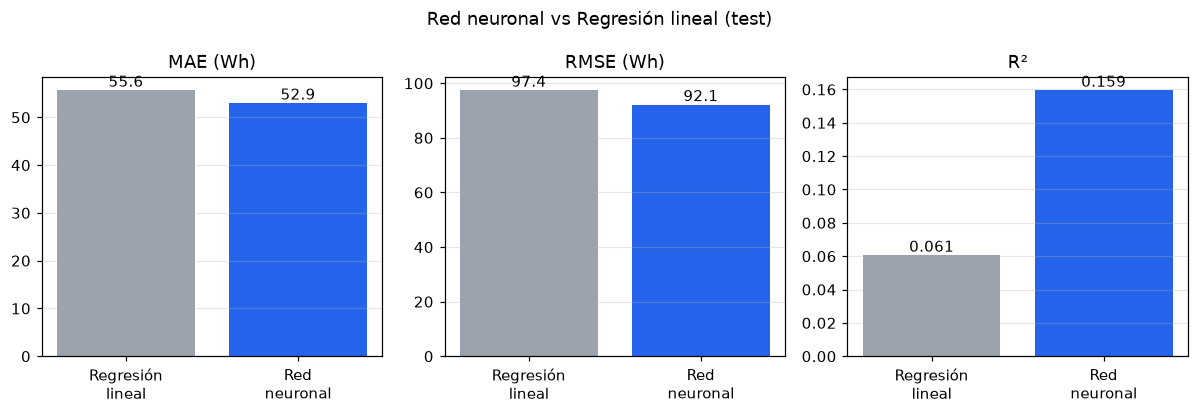

In [18]:
# Gráfica comparativa de métricas
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
modelos = ["Regresión\nlineal", "Red\nneuronal"]
colores = ["#9ca3af", "#2563eb"]
for ax, clave in zip(axes, ["MAE (Wh)", "RMSE (Wh)", "R²"]):
    valores = [m_lin[clave], m_red[clave]]
    barras = ax.bar(modelos, valores, color=colores)
    ax.bar_label(barras, fmt="%.3f" if clave == "R²" else "%.1f")
    ax.set_title(clave)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Red neuronal vs Regresión lineal (test)")
plt.tight_layout()
plt.savefig("resultados/grafica_comparacion.png", dpi=150)
plt.show()

In [19]:
# Guardar resultados: métricas en texto y un JSON listo para la página web (React)
with open("resultados/metricas.txt", "w", encoding="utf-8") as f:
    f.write("Red Neuronal Multicapa [6, 16, 8, 1] - desde cero con NumPy\n")
    f.write(f"Learning rate: {LEARNING_RATE} | Épocas: {EPOCHS} | Init: He\n\n")
    f.write("Métricas de la red neuronal:\n")
    f.write(tabla_red.round(4).to_string() + "\n\n")
    f.write("Comparación en test:\n")
    f.write(comparacion.to_string() + "\n")

paso = 10  # se guarda 1 de cada 10 épocas para que el JSON sea ligero
rng = np.random.default_rng(SEED)
muestra = rng.choice(len(real_test), size=min(500, len(real_test)), replace=False)
resultados_web = {
    "arquitectura": [6, 16, 8, 1],
    "hiperparametros": {"learning_rate": LEARNING_RATE, "epochs": EPOCHS, "init": "he"},
    "metricas": {"red_neuronal": tabla_red.round(4).to_dict(orient="index"),
                 "regresion_lineal_test": {k: round(v, 4) for k, v in m_lin.items()}},
    "loss": [{"epoca": i + 1, "train": round(red.loss_history[i], 5),
              "val": round(red.val_loss_history[i], 5)}
             for i in range(0, EPOCHS, paso)],
    "prediccion_vs_real": [{"real": float(real_test[i, 0]),
                            "prediccion": round(float(pred_test[i, 0]), 2)}
                           for i in muestra],
}
with open("resultados/resultados.json", "w", encoding="utf-8") as f:
    json.dump(resultados_web, f, ensure_ascii=False, indent=1)

print("Archivos guardados en resultados/:", sorted(os.listdir("resultados")))

Archivos guardados en resultados/: ['grafica_comparacion.png', 'grafica_loss.png', 'grafica_prediccion.png', 'metricas.txt', 'resultados.json']


=== ARCHIVO grafica_loss.png ===


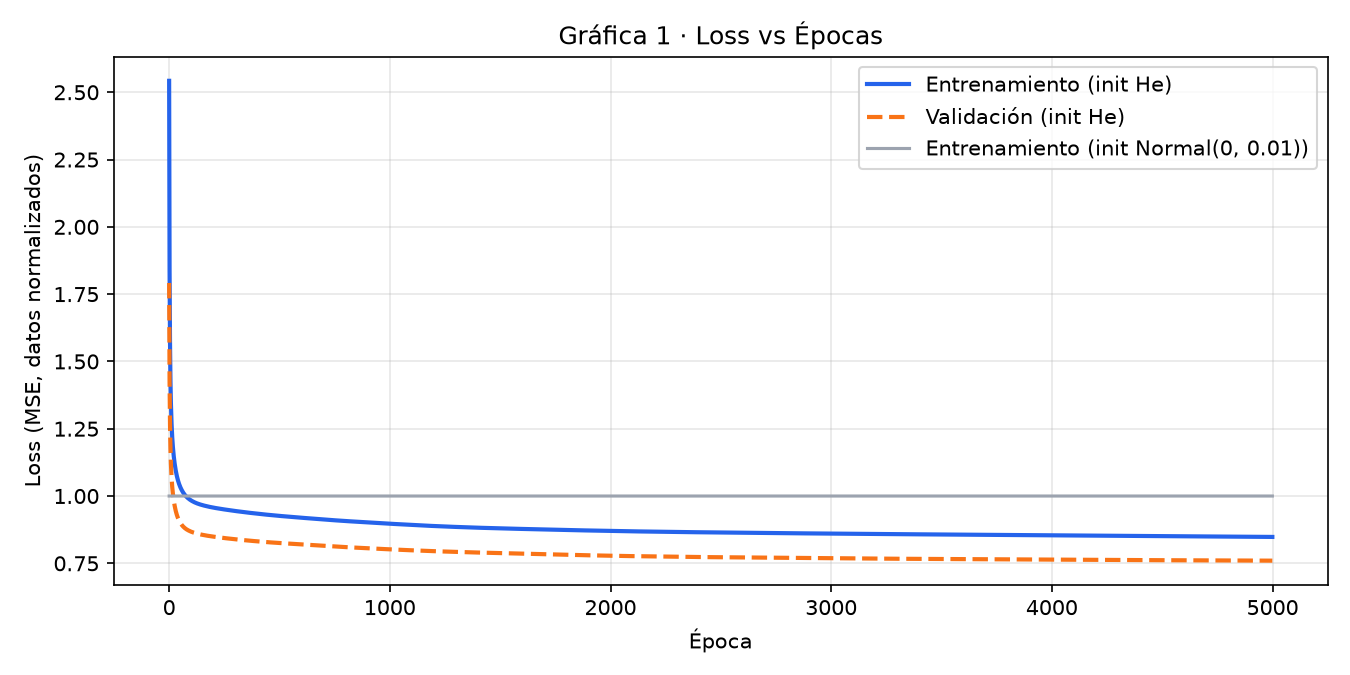

=== ARCHIVO grafica_prediccion.png ===


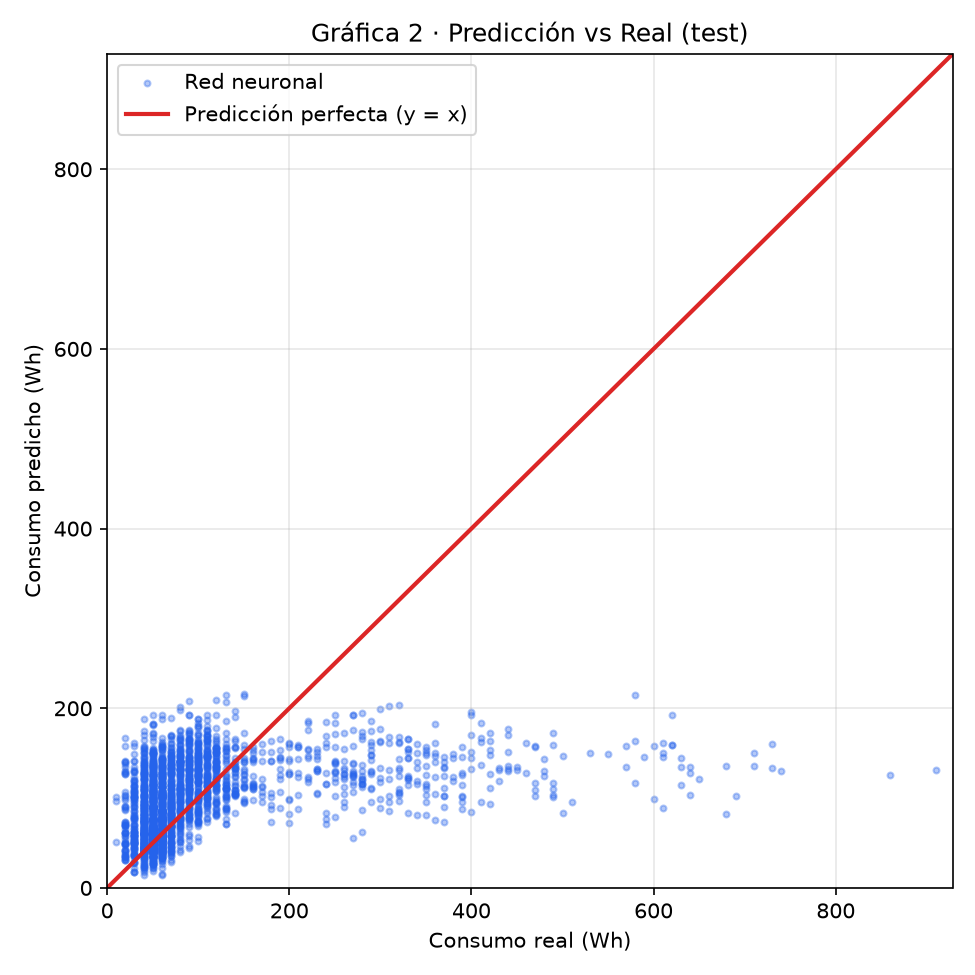

=== ARCHIVO grafica_comparacion.png ===


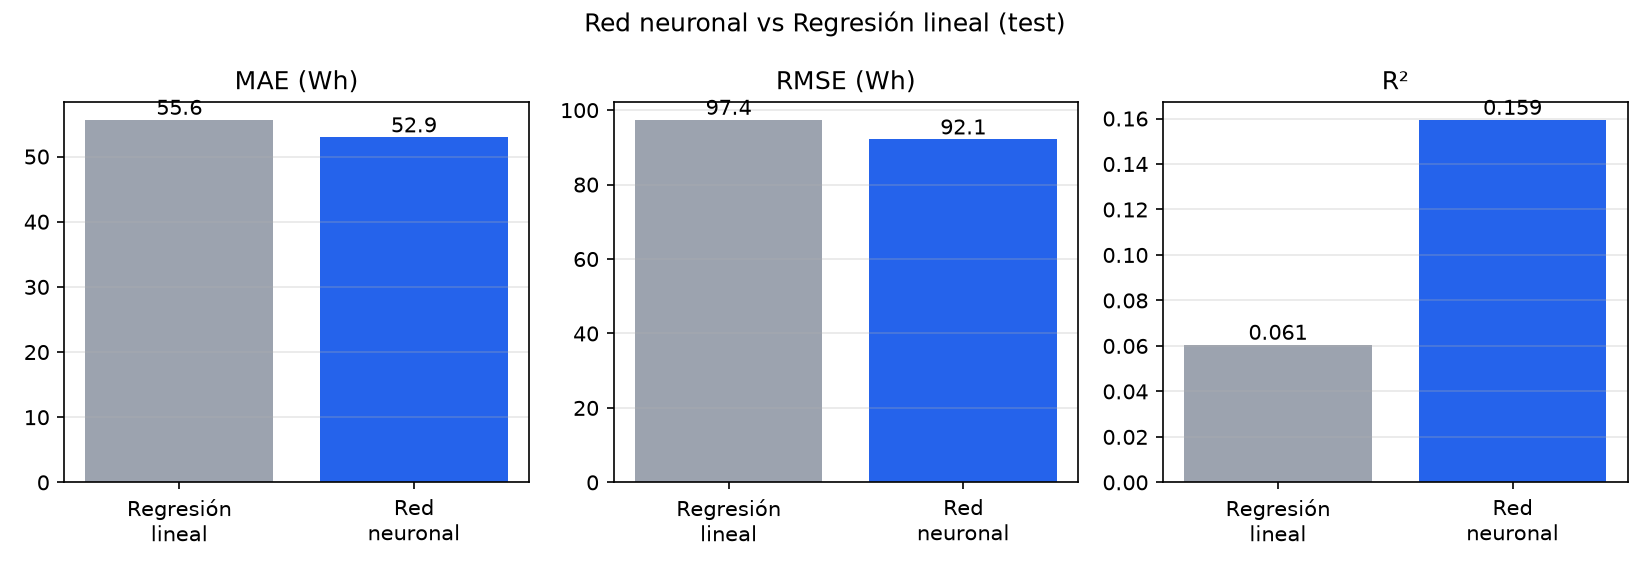

=== ARCHIVO metricas.txt ===
Red Neuronal Multicapa [6, 16, 8, 1] - desde cero con NumPy
Learning rate: 0.01 | Épocas: 5000 | Init: He

Métricas de la red neuronal:
               MAE (Wh)  RMSE (Wh)      R²
Entrenamiento   54.0079    95.8153  0.1519
Validación      52.4247    90.6961  0.1299
Prueba          52.9487    92.1307  0.1594

Comparación en test:
                           MAE (Wh)          RMSE (Wh)        R²
Red neuronal              52.948669          92.130729  0.159435
Regresión lineal          55.640796          97.401526  0.060507
Mejora de la red  4.8 % menos error  5.4 % menos error    +0.099

=== ARCHIVO resultados.json ===
{
 "arquitectura": [
  6,
  16,
  8,
  1
 ],
 "hiperparametros": {
  "learning_rate": 0.01,
  "epochs": 5000,
  "init": "he"
 },
 "metricas": {
  "red_neuronal": {
   "Entrenamiento": {
    "MAE (Wh)": 54.0079,
    "RMSE (Wh)": 95.8153,
    "R²": 0.1519
   },
   "Validación": {
    "MAE (Wh)": 52.4247,
    "RMSE (Wh)": 90.6961,
    "R²": 0.1299
 

In [20]:
# Copia de los resultados dentro del propio notebook. Si se corre con la extensión
# de Colab en VS Code, los archivos quedan en el servidor de Colab; al guardar el
# notebook, estas salidas permiten recuperarlos con codigo/extraer_resultados.py.
from IPython.display import Image, display

for nombre in ["grafica_loss.png", "grafica_prediccion.png", "grafica_comparacion.png"]:
    print(f"=== ARCHIVO {nombre} ===")
    display(Image(filename=f"resultados/{nombre}"))
for nombre in ["metricas.txt", "resultados.json"]:
    print(f"=== ARCHIVO {nombre} ===")
    with open(f"resultados/{nombre}", encoding="utf-8") as f:
        print(f.read())
print("=== FIN ===")

# Solo en la página de Google Colab: descarga resultados.zip (el navegador lo guarda
# en Descargas). En VS Code o en local no hace falta.
try:
    from google.colab import files
    import shutil
    shutil.make_archive("resultados", "zip", ".", "resultados")
    files.download("resultados.zip")
    print("✅ Descargando resultados.zip (si estás en la página de Colab, revisa Descargas)")
except Exception:
    print("Los resultados quedaron en la carpeta resultados/ y copiados arriba")

## Conclusiones

1. **La red se implementó completamente desde cero.** Forward, MSE, backpropagation y gradient descent están escritos con NumPy. El *gradient check* da una diferencia relativa de alrededor de 1e-11 entre las derivadas hechas a mano y las numéricas, así que el backpropagation es correcto.
2. **La red aprende.** En 5000 épocas el loss de entrenamiento baja de 2.54 a 0.848 y el de validación de 1.79 a 0.760 (datos normalizados). El de validación acompaña al de entrenamiento todo el tiempo, sin señales de sobreajuste. Con la inicialización original `Normal(0, 0.01)` el loss se queda en 1.000, que equivale a predecir siempre el promedio; por eso se usa la inicialización He.
3. **La red neuronal supera a la regresión lineal** en el set de prueba: MAE de 52.9 Wh contra 55.6 Wh (4.8 % menos error), RMSE de 92.1 Wh contra 97.4 Wh (5.4 % menos) y R² de 0.159 contra 0.061. La mejora es real pero pequeña: la red aprovecha relaciones no lineales, como la forma en que el consumo cambia según la hora y el día, pero estas 6 variables tienen poca información.
4. **Limitaciones (lectura honesta del R²).** Un R² de 0.159 significa que el modelo explica cerca del 16 % de la variación del consumo. Los documentos iniciales del proyecto esperaban un R² cercano a 0.92; con solo 6 variables de tiempo y clima exterior eso no es realista. El consumo de electrodomésticos depende sobre todo de lo que hacen las personas (cuándo cocinan, lavan, etc.), que no está en los datos, y tiene picos muy altos (ver el histograma de la Sección 1). En la Gráfica 2 se ve el efecto: la red casi nunca predice más de 200 Wh, aunque hay consumos reales de más de 700 Wh, así que en los picos queda muy por debajo de la diagonal.
5. **Mejoras posibles:** agregar el consumo de los registros anteriores (*lags*), codificar la hora de forma cíclica (seno/coseno), usar las temperaturas y humedades interiores del dataset, entrenar con mini-batches o el optimizador Adam, y aplicar *early stopping* con el set de validación.